<div style="display: flex; justify-content: space-between; align-items: flex-start; border-bottom: 2px solid #555555; padding-bottom: 15px; margin-bottom: -8px;">
    <div style="width: 50%;">
        <h2>
            <span style="color: #B30033;">▍</span>TRABAJO DE FIN DE MÁSTER
        </h2>
        <h1 style="margin-top: -10px;">MARCO DE TRABAJO DE RECOMENDACIÓN DE TALENTO PARA LA FORMACIÓN DE EQUIPOS EN PROYECTOS DE INGENIERÍA DEL SOFTWARE</h1>
    </div>
    <div style="width: 50%; text-align: right;">
        <div style="display: flex; justify-content: space-between; align-items: flex-start; margin-top: 30px;">
            <div style="width: 20%;"></div>
            <div style="width: 80%; border-left: 2px solid #555555; padding-left: 20px;">
                <div style="margin-bottom: 20px;">
                    <p style="margin: 0; font-size: 1.4em; font-weight: bold;">
                        Profesores
                    </p>
                </div>
                <div style="margin-top: 8px; text-align: right;">
                    <span style="display: block; font-size: 1em; color: #D0D0D0;">
                        Aurora Vizcaíno Barceló
                    </span>
                    <span style="display: block; font-size: 1em; color: #D0D0D0; margin-top: 5px;">
                        Julio Alberto López Gómez
                    </span>
                </div>
            </div>
        </div>
    </div>
</div>

<div style="margin-top: 30px; padding: 20px; background-color: rgba(179, 0, 51, 0.05); border-left: 4px solid #B30033; border-radius: 4px;">
    <h3 style="margin-top: 0; color: #B30033;">🎯 Objetivo de esta Libreta (Fase 3: Minería de Reglas de Asociación)</h3>
    <p style="font-size: 1.1em; line-height: 1.6; color: #E0E0E0;">
        El objetivo de esta tercera libreta es <strong>descubrir patrones ocultos y relaciones entre los distintos datos ya procesados de la matriz, así como preferencias y características de la personalidad</strong> de los diferentes candidatos, utilizando algoritmos de aprendizaje no supervisados basados en reglas.
    </p>
    <ul style="font-size: 1.1em; line-height: 1.6; color: #D0D0D0; margin-bottom: 0;">
        <li><strong>Carga y optimización:</strong> Se importa la matriz transaccional generada en la libreta 2 y se convierte a booleana para así ser más eficiente en memoria.</li>
        <li><strong>Extracción de los Itemsets Frecuentes:</strong> A lo largo de la libreta vamos a aplicar 3 algoritmos principales y a compararlos entre ellos. Estos algoritmos, todos de minería de reglas de asociación son: <strong>Apriori</strong>, <strong>FP-Growth</strong> y <strong>Eclat</strong>. Para elegir cuál conviene más evaluaremos tanto la equivalencia de los resultados obtenidos como su eficiencia computacional y tiempos.</li>
        <li><strong>Generación de Reglas:</strong> Creamos reglas direccionales (Antecedente → Consecuente) basadas en métricas de probabilidad condicional, como son la (<em>Confianza</em>) y la fuerza de asociación (<em>Lift</em>).</li>
        <li><strong>Filtrado por Relevancia:</strong> Posteriormente vamos a depurar reglas que consideramos innecesarias, excluyendo aquellas que en su mayoría tengan valores nulos y aquellas circulares respecto a la propia construcción de los proxies de personalidad (Big Five).</li>
        <li><strong>Exportación del modelo:</strong> Guardaremos las reglas finales como "Base de Conocimiento" para así cruzarla posteriormente con las reglas expertas.</li>
    </ul>
</div>
<br/>

<div style="border-bottom: 2px solid #555555; padding-bottom: 25px; margin-bottom: 10px">
    <div style="display: flex; align-items: center; margin-bottom: 10px;">
        <span style="color: #B30033; font-size: 1.5em; margin-right: 10px;">▍</span>
        <h3 style="margin: 0; font-size: 1.4em; font-weight: bold">
            Realizado por Miguel Ángel Sánchez-Medina Camacho <span style="font-size: 0.7em; font-style: italic; font-weight: normal;"></span>
        </h3>
    </div>
</div>

### 3.1. Configuración del Entorno y carga de la Matriz Transaccional

Primero como siempre importamos todas las librerías necesarias. Para esta parte del proyecto, haremos uso de las siguientes:

* `mlxtend` para la minería de reglas, de ella importamos apriori y fpgrowth.
* Después importamos `pyECLAT` para posteriormente evaluar este algoritmo.
* Cargamos la matriz transaccional y la convertimos a booleana, para que tenga únicamente valores `True`/`False` ya que es el formato esperado por las funciones de minería de reglas de `mlxtend` y permite trabajar directamente con la representación binaria de presencia/ausencia.

In [1]:
import os
import sys
import warnings
import time

sys.path.append(os.path.abspath(os.path.join('../..')))
from src.soft_skills import config, utils_soft

import pandas as pd
from mlxtend.frequent_patterns import apriori,fpgrowth, association_rules
from IPython.display import display
from pyECLAT import ECLAT
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

df_matriz = pd.read_csv(config.MATRIZ_TRANSACCIONAL_PATH, index_col='CandidateId')
df_matriz = df_matriz.fillna(0).astype(bool)

print(f"Dimensiones matriz: {df_matriz.shape}")
display(df_matriz.head(3))

Dimensiones matriz: (88778, 205)


,WorkWeekHrs_is_missing,CodeRevHrs_is_missing,WorkChallenge_Distracting work environment,WorkChallenge_Meetings,WorkChallenge_Being tasked with non-development work,WorkChallenge_Not enough people for the workload,WorkChallenge_Lack of support from management,WorkChallenge_Inadequate access to necessary tools,WorkChallenge_Toxic work environment,WorkChallenge_Time spent commuting,...,Apertura_Nivel_Bajo,Apertura_Nivel_Medio,WorkWeekHrs_Bin_35-45h,WorkWeekHrs_Bin_45-55h,WorkWeekHrs_Bin_<35h,WorkWeekHrs_Bin_>55h,CodeRevHrs_Bin_0-2h,CodeRevHrs_Bin_0h (No revisa nada de código),CodeRevHrs_Bin_2-5h,CodeRevHrs_Bin_>5h
CandidateId,,,,,,,,,,,,,,,,,,,,,
1,True,True,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
2,True,True,False,False,False,False,False,False,False,False,...,False,True,False,False,False,False,False,False,False,False
3,False,True,True,False,False,False,True,True,False,False,...,False,True,True,False,False,False,False,False,False,False


### 3.2. Generación de Itemsets Frecuentes — 1er algoritmo --> Apriori

Propuesto por Agrawal y Srikant en 1994, **Apriori** es uno de los primeros algoritmos desarrollados para identificar itemsets frecuentes en bases de datos con transacciones, y posteriormente permite generar reglas de asociación. Este algoritmo consta de 2 etapas: primero identifica todos los itemsets que ocurren con una frecuencia por encima de un determinado límite y posteriormente a partir de ahí construye combinaciones cada vez más grandes (2 ítems, 3 ítems...), descartando en cada paso cualquier combinación con un subconjunto no frecuente (*downward closure*).

**Conceptos clave utilizados en esta libreta:**
- **Soporte** (`support`): Es el número de transacciones que contienen el itemset dividido entre el total de transacciones. En nuestro caso, la proporción de candidatos en los que aparece un itemset.
- **Confianza** (`confidence`): Podemos definirlo como la probabilidad de que se cumpla el consecuente de una regla, una vez que se cumple el antecedente. Es una probabilidad condicional, no simétrica.
 - **Lift**: Cuánto más frecuente es la combinación de antecedente y consecuente de lo que cabría esperar si fueran independientes. Un lift de 1 indica independencia, pero si ese valor está por encima de 1 tiene asociación positiva.

 **Configuración de hiperparámetros:**

 En cuanto a los parámetros elegidos para la minería de reglas, vamos a utilizar de forma predefinida `max_len=4`, porque limitar el tamaño máximo de un itemset a 4 ítems combinados ya es suficiente para mantener las reglas interpretables en esta primera exploración. Esto es porque las reglas que combinan un número elevado de ítems pueden resultar más difíciles de interpretar y además actúa como control de memoria, de la misma forma que incluimos `low_memory=True`. Para el `min_support` no tenemos tan claro qué valor nos interesa más, por ello, vamos a realizar una ejecución con varios posibles valores y comparar los resultados en base a itemsets obtenidos y tiempos, así decidimos cuál nos interesa más para nuestras fases posteriores.


In [2]:
valores_min_support = [0.20, 0.18, 0.15, 0.12, 0.10, 0.08, 0.05]
df_crecimiento, ms_codo = utils_soft.barrido_min_support(df_matriz, valores_min_support, algoritmo=apriori, low_memory=True)
display(df_crecimiento)
print(f"Mayor salto de complejidad en min_support={ms_codo}")

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,770,4.63,NaN,NaN,NaN
1,0.18,1134,6.20,364.0,0.02,182.000000
2,0.15,2188,10.17,1054.0,0.03,351.333333
3,0.12,4634,16.95,2446.0,0.03,815.333333
4,0.10,8276,25.64,3642.0,0.02,1821.000000
5,0.08,15872,39.19,7596.0,0.02,3798.000000
6,0.05,52682,86.84,36810.0,0.03,12270.000000


Mayor salto de complejidad en min_support=0.05


Como vemos, al disminuir el valor de min_support aumenta rápidamente el número de itemsets y también el tiempo de ejecución. En 0.08 ya obtenemos 15.872 itemsets, mientras que en 0.05 el número aumenta hasta 52.682, incrementando considerablemente la complejidad del análisis.

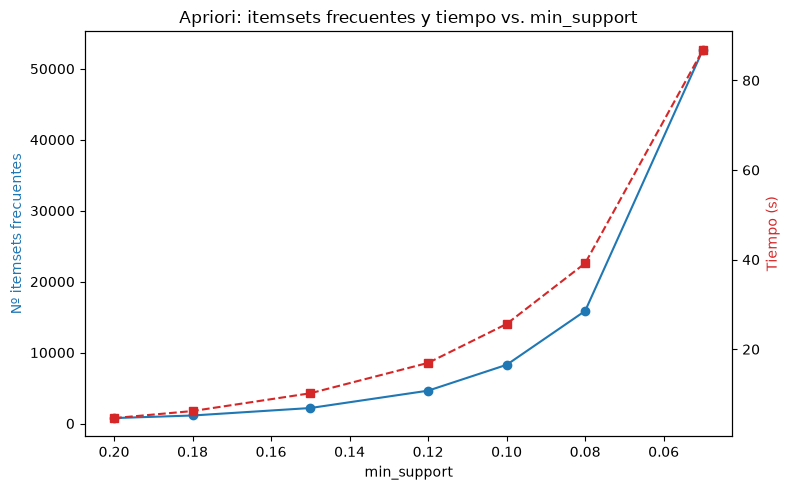

In [3]:
def graficar_barrido(df_sweep, titulo):
    fig, ax1 = plt.subplots(figsize=(8, 5))
    ax1.plot(df_sweep['min_support'], df_sweep['n_itemsets'], marker='o', color='tab:blue')
    ax1.set_xlabel('min_support')
    ax1.set_ylabel('Nº itemsets frecuentes', color='tab:blue')
    ax1.invert_xaxis()
    ax2 = ax1.twinx()
    ax2.plot(df_sweep['min_support'], df_sweep['tiempo_s'], marker='s', color='tab:red', linestyle='--')
    ax2.set_ylabel('Tiempo (s)', color='tab:red')
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

graficar_barrido(df_crecimiento, 'Apriori: itemsets frecuentes y tiempo vs. min_support')

Si observamos la gráfica, vemos que los valores entre 0.12 y 0.08 parecen ofrecer un mejor equilibrio entre el número de itemsets obtenidos y el tiempo de ejecución. Valores superiores generan un número más reducido de patrones, mientras que al disminuir por debajo de 0.08 el número de itemsets y el coste computacional aumentan considerablemente.

Ante esta situación, vamos a comparar directamente los valores 0.12 y 0.08, situados en los extremos del intervalo considerado, para evaluar el equilibrio entre cantidad de itemsets, reglas generadas y coste computacional.

In [4]:
candidatos_min_support = [0.12, 0.08]
resumen_candidatos = []

for ms in candidatos_min_support:
    its = apriori(df_matriz, min_support=ms, use_colnames=True, max_len=4, low_memory=True, verbose=0)
    rgs = association_rules(its, metric="confidence", min_threshold=0.6)
    resumen_candidatos.append({'min_support': ms, 'n_itemsets': len(its), 'n_reglas': len(rgs)})
    del its, rgs

df_resumen_candidatos = pd.DataFrame(resumen_candidatos)
display(df_resumen_candidatos)
print(f"\nAl bajar de 0.12 a 0.08: itemsets x{df_resumen_candidatos.loc[1,'n_itemsets']/df_resumen_candidatos.loc[0,'n_itemsets']:.1f}, "
      f"reglas x{df_resumen_candidatos.loc[1,'n_reglas']/df_resumen_candidatos.loc[0,'n_reglas']:.1f}")

,min_support,n_itemsets,n_reglas
0,0.12,4634,11229
1,0.08,15872,34781



Al bajar de 0.12 a 0.08: itemsets x3.4, reglas x3.1


En principio con 0.08 son muchos más itemsets y reglas de las que necesitamos, ya que más de 15.5k sería muy complejo, debemos rebajar las espectativas y elegimos 0.12 para Apriori, a esperas de ver qué elegiremos en el resto de algoritmos, la idea aquí es elegir un valor de `min_support` para los 3 y así determinar bajo las mismas condiciones cual nos aporta más y se adapta mejor al proyecto

In [5]:
itemsets_frecuentes = apriori(
    df_matriz, min_support=0.12, use_colnames=True,
    max_len=4, low_memory=True, verbose=1
)

pd.set_option('display.max_colwidth', None)
display(itemsets_frecuentes.sort_values('support', ascending=False).head(20))

Processing 8585 combinations | Sampling itemset size 4


,support,itemsets
20,0.802643,frozenset({Hobbyist_Yes})
25,0.725461,frozenset({Employment_Employed full-time})
78,0.705817,frozenset({WelcomeChange_Just as welcome now as I felt last year})
65,0.618824,frozenset({BetterLife_Yes})
80,0.605803,frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})
71,0.595418,frozenset({Extraversion_In real life (in person)})
392,0.572022,"frozenset({Hobbyist_Yes, Employment_Employed full-time})"
433,0.564464,"frozenset({WelcomeChange_Just as welcome now as I felt last year, Hobbyist_Yes})"
529,0.558832,"frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%), Employment_Employed full-time})"
56,0.545450,"frozenset({CodeRev_Yes, because I see value in code review})"


Una vez tenemos el listado con el top 20, vemos que en base al número de soporte, los itemsets individuales dominan las posiciones superiores del ranking de soporte. Esto es esperable, ya que el soporte de un conjunto de ítems no puede superar el soporte de ninguno de sus elementos individuales.

* Destacan `Hobbyist_Yes` (con un 80,3%) Nos dice que la inmensa mayoría de los candidatos programa también como afición, no solo en su empleo. Segundo está `Employment_Employed full-time` (72,5%, señala los empleados que están a tiempo completo) y `WelcomeChange_Just as welcome...` tercero (70,6%, sentido de pertenencia estable a la comunidad)

* Un dato relevante para nuestro proyecto es que `JobFactors_Languages, frameworks, and other technologies I'd be working with` (48,4%) es con diferencia el factor de decisión de empleo más citado entre las respuestas multivalor de `JobFactors` (algo que también veíamos en libretas anteriores). Esto nos confirma que el stack tecnológico sigue siendo el criterio prioritario de los candidatos a la hora de elegir un proyecto, algo muy relevante para el matching final.

### 3.3. Filtrado de reglas: estructura de nulos

Antes de seguir interpretando las reglas obtenidas, vamos a realizar una fase de depuración para identificar y eliminar aquellas reglas que puedan introducir ruido o aportar información poco útil para los objetivos del proyecto.

En la libreta 1 correspondiente al EDA, vimos que había muchos datos en los proxies de personalidad que tenían mucha correlación con la ausencia de datos en variables laborales como `WorkRemote`, `WorkWeekHrs`, `CodeRevHrs`. En ellas se identifican al mismo subgrupo de candidatos que no están empleados, como pueden ser estudiantes o profesionales desempleados. También pueden contener valores de personas que no quisieron responder, pero para nosotros todos son aquellos que no tienen trabajo.

Sin embargo, aquí hay algunas de esas reglas que deben ser revisadas ya que pueden tener un nivel de confianza muy alto (p.ej  **confianza = 1.000**) que afecten a los resultados de todo el conjunto de reglas. Otro problema a tener en cuenta es que las reglas expertas no contemplan la opción de que exista "ausencia de datos", por lo que sus condiciones se basan en niveles reales de los rasgos (neuroticismo alto/bajo), no en si el dato se conoce o no. Dejar estas reglas mezcladas con el resto sesgaría cualquier comparación posterior no sería buena praxis ya que ocuparían las primeras posiciones por lift sin tener ningún equivalente contra el que contrastarse.

Todo esto lo trataremos más adelante en la libreta

In [6]:
reglas_asociacion = association_rules(itemsets_frecuentes, metric="confidence", min_threshold=0.6)

reglas_asociacion = reglas_asociacion.sort_values('lift', ascending=False)
print(f"Reglas de asociacion obtenidas: {len(reglas_asociacion)}")
display(reglas_asociacion[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(20))

Reglas de asociacion obtenidas: 11229


,antecedents,consequents,support,confidence,lift
4162,"frozenset({WorkWeekHrs_is_missing, WelcomeChange_Just as welcome now as I felt last year})","frozenset({Amabilidad_Nivel_Medio, CodeRevHrs_is_missing})",0.120818,0.743416,5.415076
4161,"frozenset({Amabilidad_Nivel_Medio, CodeRevHrs_is_missing})","frozenset({WorkWeekHrs_is_missing, WelcomeChange_Just as welcome now as I felt last year})",0.120818,0.880046,5.415076
4274,"frozenset({WorkWeekHrs_Bin_35-45h, CodeRevHrs_is_missing, Amabilidad_Nivel_Bajo})",frozenset({CodeRev_No}),0.120920,0.968601,5.171734
4281,frozenset({CodeRev_No}),"frozenset({WorkWeekHrs_Bin_35-45h, CodeRevHrs_is_missing, Amabilidad_Nivel_Bajo})",0.120920,0.645637,5.171734
4262,frozenset({CodeRev_No}),"frozenset({Amabilidad_Nivel_Bajo, CodeRevHrs_is_missing, WelcomeChange_Just as welcome now as I felt last year})",0.141060,0.753173,5.149415
4253,"frozenset({Amabilidad_Nivel_Bajo, CodeRevHrs_is_missing, WelcomeChange_Just as welcome now as I felt last year})",frozenset({CodeRev_No}),0.141060,0.964420,5.149415
4272,frozenset({CodeRev_No}),"frozenset({Amabilidad_Nivel_Bajo, CodeRevHrs_is_missing, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",0.134943,0.720515,5.073032
4264,"frozenset({Amabilidad_Nivel_Bajo, CodeRevHrs_is_missing, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({CodeRev_No}),0.134943,0.950115,5.073032
4187,frozenset({Neuroticismo_Nivel_Desconocido}),"frozenset({WorkWeekHrs_is_missing, WorkRemote_Bucket_Desconocido (Sin datos), Hobbyist_Yes})",0.154385,0.860335,4.912138
4176,"frozenset({WorkWeekHrs_is_missing, WorkRemote_Bucket_Desconocido (Sin datos), Hobbyist_Yes})",frozenset({Neuroticismo_Nivel_Desconocido}),0.154385,0.881471,4.912138


**Análisis de las reglas obtenidas (sin filtrar):**

Con `min_support=0.12` y `min_confidence=0.6`, Apriori genera **11.229 reglas**. Sin embargo, las 20 con mayor lift son combinaciones entre `Neuroticismo_Nivel_Desconocido`, `WorkWeekHrs_is_missing`, `CodeRevHrs_is_missing` y `WorkRemote_Bucket_Desconocido (Sin datos)`.

Otras observaciones, como hemos comentado anteriormente son:

1. **Varias reglas alcanzan confianza = 1.000** (ej. `{Neuroticismo_Nivel_Desconocido} → {WorkWeekHrs_is_missing, WorkRemote_Bucket_Desconocido, CodeRevHrs_is_missing}`, fila 4173), por lo que todos los candidatos con neuroticismo desconocido tiene también esas tres variables laborales sin dato.

2. **Muchas filas aparecen en pares con el mismo lift pero distinta confianza** (ej. filas 4186 y 4179, ambas con lift 4.912138). Esto es posible si el lift es simétrico (`lift(A→B) = lift(B→A)`), porque ambos se calculan como `soporte(A∪B) / (soporte(A) × soporte(B))`. Por el contrario, la confianza no lo es, por eso el mismo itemset genera dos filas con lift idéntico pero confianza distinta según qué lado se tome como antecedente.

3. **Los valores de lift de esta tabla son los más altos de todo el conjunto de reglas** muy por encima de lo que veremos más adelante en las reglas ya tratadas. Esto es porque la presencia de nulos afecta fuertemente a todo el dataset y lo trataremos a lo largo de esta fase.

### 3.3.1. Filtrado de reglas con elementos nulos

Tal cual como hemos comentado antes, se abordará la presencia de valores nulos para evitar que el algoritmo interprete como relevantes asociaciones vacías. Para ello, haremos el siguiente tratamiento:

Primero identificamos con los sufijos `_is_missing` o `Desconocido` en cualquier ítem de la regla (antecedente o consecuente), y después separamos en un subconjunto de reglas sustantivas: (`reglas_sustantivas`) en vez de borrarlas, así podemos preservar los dos listados:

- El conjunto excluido confirma la consistencia del hallazgo ya reportado en el EDA sobre la estructura no aleatoria del missingness.
- El conjunto `reglas_sustantivas` (10.911 de las 11.229 reglas totales) queda libre de este efecto y es el que se usará en el resto del análisis.

In [7]:
def contiene_item_missing(frozenset_items):
    return any('is_missing' in item or 'Desconocido' in item for item in frozenset_items)

reglas_asociacion['tiene_missing'] = reglas_asociacion.apply(lambda row: contiene_item_missing(row['antecedents']) or contiene_item_missing(row['consequents']),axis=1)
reglas_sustantivas = reglas_asociacion[~reglas_asociacion['tiene_missing']].sort_values('lift', ascending=False)

print(f"Reglas totales: {len(reglas_asociacion)}")
print(f"Reglas con nulos: {reglas_asociacion['tiene_missing'].sum()}")
print(f"Reglas sustantivas restantes: {len(reglas_sustantivas)}")
display(reglas_sustantivas[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas totales: 11229
Reglas con nulos: 318
Reglas sustantivas restantes: 10911


,antecedents,consequents,support,confidence,lift
10391,"frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})","frozenset({Amabilidad_Nivel_Alto, WelcomeChange_Just as welcome now as I felt last year})",0.140147,0.743472,4.689778
10389,"frozenset({Amabilidad_Nivel_Alto, WelcomeChange_Just as welcome now as I felt last year})","frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})",0.140147,0.884041,4.689778
2302,"frozenset({BetterLife_No, OpenSourcer_Never})",frozenset({Apertura_Nivel_Bajo}),0.129548,1.000000,4.314638
10410,"frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})","frozenset({WorkWeekHrs_Bin_35-45h, Amabilidad_Nivel_Alto})",0.130900,0.694413,4.048105
10406,"frozenset({WorkWeekHrs_Bin_35-45h, Amabilidad_Nivel_Alto})","frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})",0.130900,0.763084,4.048105
10400,"frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})","frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",0.143673,0.762175,3.964400
10398,"frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})",0.143673,0.747305,3.964400
3760,frozenset({CodeRev_No}),"frozenset({Amabilidad_Nivel_Bajo, WelcomeChange_Just as welcome now as I felt last year})",0.141060,0.753173,3.837311
3757,"frozenset({Amabilidad_Nivel_Bajo, WelcomeChange_Just as welcome now as I felt last year})",frozenset({CodeRev_No}),0.141060,0.718680,3.837311
8666,"frozenset({Amabilidad_Nivel_Alto, Employment_Employed full-time})","frozenset({CodeRev_Yes, because I see value in code review, MgrIdiot_Very confident})",0.169952,0.720432,3.821839


**Análisis del top-15 de reglas sustantivas (antes del filtro de circularidad)**

Una vez hecho el filtro con nulos, vemos que el nuevo top en base al lift está dominado por `Amabilidad_Nivel_Alto` (o `_Medio`) y **sus propias variables constituyentes**: `MgrIdiot_Very confident`, `CodeRev_Yes... because I see value...` y `WelcomeChange_Just as welcome...`. Varias reglas alcanzan de nuevo **confianza = 1.000**. Aquí este patrón no es coincidencia, si no que el algoritmo está redescubiendo (de forma correcta) la fórmula que utilizamos para la construcción del proxy, lo que es matemáticamente esperable. Por ello, se genera un problema de circularidad que hace que quien puntúe algo en `WelcomeChange` y `MgrIdiot` (dos de los tres ingredientes) tienda también a tener `Amabilidad_Nivel_Alto`.

### 3.3.2. Filtrado de reglas de circularidad de los proxies

Para esta celda queda pendiente solucionar el problema de **circularidad**. Como hemos explicado antes, hay reglas que relacionan un proxy de personalidad (`Neuroticismo_Nivel`, `Amabilidad_Nivel`, `Apertura_Nivel`) con alguna de las variables que se usaron para calcularlo en la Libreta 1, las cuales generan reglas de confianza casi perfectas y no aportan nada en cuanto a comportamientos.

**Diccionario de referencia (`INPUTS_BIGFIVE`):** Aquí vamos a aplicar las columnas originales que se promediaron para obtener su `_Score` en `calcular_proxies_bigfive()`:
- `Neuroticismo` ← `ImpSyn`, `JobSat`, `CareerSat`, `WorkWeekHrs_Bin`
- `Amabilidad` ← `WelcomeChange`, `CodeRev`, `MgrIdiot`
- `Apertura` ← `Hobbyist`, `OpenSourcer`, `BetterLife`

En la función `es_regla_circular` lo que hacemos es que para cada regla se recorren todos sus ítems (antecedente y consecuente juntos) en busca de dos señales: 

* Primero vemos qué rasgos aparecen como nivel derivado (ítems que empiezan por `Neuroticismo_Nivel_`, etc.) 
* Segundo, identificamos qué rasgos tienen alguno de sus componentes originales presentes en la regla. Si el mismo rasgo aparece en ambos conjuntos simultáneamente, la regla es circular, ya está combinando el resultado con uno de sus propios ingredientes.

In [8]:
INPUTS_BIGFIVE = {
    'Neuroticismo': ['ImpSyn', 'JobSat', 'CareerSat', 'WorkWeekHrs_Bin'],
    'Amabilidad':   ['WelcomeChange', 'CodeRev', 'MgrIdiot'],
    'Apertura':     ['Hobbyist', 'OpenSourcer', 'BetterLife'],
}

def es_regla_circular(frozenset_items):
    rasgos_presentes = set()
    inputs_presentes = set()
    for item in frozenset_items:
        for rasgo in INPUTS_BIGFIVE:
            if item.startswith(f'{rasgo}_Nivel_'):
                rasgos_presentes.add(rasgo)
        for rasgo, inputs in INPUTS_BIGFIVE.items():
            if any(item.startswith(f'{col}_') for col in inputs):
                inputs_presentes.add(rasgo)
    return len(rasgos_presentes & inputs_presentes) > 0

reglas_sustantivas['es_circular'] = reglas_sustantivas.apply(
    lambda row: es_regla_circular(row['antecedents'] | row['consequents']),
    axis=1
)

reglas_limpias = reglas_sustantivas[~reglas_sustantivas['es_circular']].sort_values('lift', ascending=False)

print(f"Reglas sustantivas previas al filtro: {len(reglas_sustantivas)}")
print(f"Reglas circulares (proxy vs. sus propios componentes): {reglas_sustantivas['es_circular'].sum()}")
print(f"Reglas limpias: {len(reglas_limpias)}")
display(reglas_limpias[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas sustantivas previas al filtro: 10911
Reglas circulares (proxy vs. sus propios componentes): 1336
Reglas limpias: 9575


,antecedents,consequents,support,confidence,lift
8310,"frozenset({WorkWeekHrs_Bin_35-45h, JobSat_Very satisfied})","frozenset({CareerSat_Very satisfied, Employment_Employed full-time})",0.129142,0.738249,2.615228
8305,"frozenset({JobSat_Very satisfied, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({CareerSat_Very satisfied, Employment_Employed full-time})",0.137726,0.736256,2.608169
8304,"frozenset({JobSat_Very satisfied, Employment_Employed full-time})","frozenset({CareerSat_Very satisfied, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",0.137726,0.634938,2.595714
7180,"frozenset({JobSat_Very satisfied, Hobbyist_Yes})","frozenset({CareerSat_Very satisfied, CodeRev_Yes, because I see value in code review})",0.124152,0.610739,2.549737
3062,"frozenset({WorkLoc_Office, CareerSat_Very satisfied})",frozenset({JobSat_Very satisfied}),0.125515,0.642211,2.539381
8291,"frozenset({JobSat_Very satisfied, Employment_Employed full-time})","frozenset({CareerSat_Very satisfied, CodeRev_Yes, because I see value in code review})",0.131136,0.604559,2.523939
8290,"frozenset({JobSat_Very satisfied, CodeRev_Yes, because I see value in code review})","frozenset({CareerSat_Very satisfied, Employment_Employed full-time})",0.131136,0.706904,2.504190
8297,"frozenset({JobSat_Very satisfied, Employment_Employed full-time})","frozenset({CareerSat_Very satisfied, WelcomeChange_Just as welcome now as I felt last year})",0.133186,0.614010,2.494994
7176,"frozenset({JobSat_Very satisfied, CodeRev_Yes, because I see value in code review, Hobbyist_Yes})",frozenset({CareerSat_Very satisfied}),0.124152,0.818992,2.492322
3067,"frozenset({JobSat_Very satisfied, BetterLife_Yes})",frozenset({CareerSat_Very satisfied}),0.131823,0.818220,2.489971


**Análisis del top-15 de reglas limpias (sin nulos ni circularidad)**

Una vez tenemos un primer listado sin nulos ni circularidad, vemos lo siguiente:

**`JobSat_Very satisfied` ↔ `CareerSat_Very satisfied` domina por completo el bloque** (las 15 reglas mostradas combinan ambas variables, una como antecedente y otra como consecuente, o viceversa), en múltiples combinaciones con `Hobbyist_Yes`, `Employment_Employed full-time`, `WorkLoc_Office`, `CodeRev_Yes... because I see value...`, `BetterLife_Yes` y `WelcomeChange_Just as welcome...`. Este es un resultado coherente, ya que la satisfacción con el puesto actual y la satisfacción con la trayectoria profesional están relacionadas, aunque son preguntas distintas de la encuesta, por lo que la regla no es circular pese a que `JobSat` sí es uno de los inputs de `Neuroticismo_Score`.

### 3.3.3. Reglas que involucran los proxies de Big Five

Despues de excluir las reglas que estaban dominadas por nulos y las circulares por los propios proxies, nos quedan un total de **9.575 reglas limpias**, pero hay un problema, es que en ninguna de las que aparecían en los primeros puestos por lift mencionaba `Neuroticismo_Nivel`, `Amabilidad_Nivel` ni `Apertura_Nivel`. Por ello, tendremos problemas más adelante al comparar las reglas obtenidas con las reglas expertas, que vamos a articular en torno a 3 rasgos: si se ordena solo por lift global, quedan enterradas bajo patrones más genéricos (satisfacción laboral, ubicación de trabajo, etc.).

Por lo tanto, filtramos `reglas_limpias` con el objetivo de aislar el subconjunto donde algún proxy de Big Five aparece en cualquiera de sus niveles (antecedente o consecuente).

In [9]:
def contiene_proxy_bigfive(frozenset_items):
    return any(item.startswith(('Neuroticismo_Nivel_', 'Amabilidad_Nivel_', 'Apertura_Nivel_')) for item in frozenset_items)

reglas_con_proxy = reglas_limpias[
    reglas_limpias.apply(lambda row: contiene_proxy_bigfive(row['antecedents'] | row['consequents']), axis=1)
].sort_values('lift', ascending=False)

print(f"Reglas limpias que sí involucran algún proxy de Big Five: {len(reglas_con_proxy)}")
display(reglas_con_proxy[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas limpias que sí involucran algún proxy de Big Five: 849


,antecedents,consequents,support,confidence,lift
9483,"frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({WorkLoc_Office, Employment_Employed full-time})",0.133107,0.692348,1.671115
5604,"frozenset({Neuroticismo_Nivel_Medio, JobFactors_Office environment or company culture, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({WorkLoc_Office}),0.120875,0.753634,1.648260
10860,"frozenset({Extraversion_In real life (in person), Neuroticismo_Nivel_Medio, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({WorkLoc_Office}),0.138638,0.731226,1.599251
10862,"frozenset({Neuroticismo_Nivel_Medio, WorkLoc_Office})","frozenset({Extraversion_In real life (in person), WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",0.138638,0.612552,1.595830
9478,"frozenset({Neuroticismo_Nivel_Medio, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({WorkLoc_Office, Employment_Employed full-time})",0.193133,0.657968,1.588133
9481,"frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%), Amabilidad_Nivel_Alto, Employment_Employed full-time})",frozenset({WorkLoc_Office}),0.133107,0.725236,1.586151
3702,"frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({WorkLoc_Office}),0.138886,0.722404,1.579957
5605,"frozenset({Neuroticismo_Nivel_Medio, JobFactors_Office environment or company culture})","frozenset({WorkLoc_Office, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",0.120875,0.628978,1.554550
5453,"frozenset({Neuroticismo_Nivel_Medio, JobFactors_Office environment or company culture, Employment_Employed full-time})",frozenset({WorkLoc_Office}),0.122992,0.709671,1.552108
10792,"frozenset({Neuroticismo_Nivel_Medio, CodeRev_Yes, because I see value in code review, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({WorkLoc_Office}),0.145453,0.707562,1.547495


**Análisis del top-15 de reglas con proxies de Big Five**

Vemos que **11 de las 15 reglas están dominadas por el nivel `_Medio`** (todas de `Neuroticismo_Nivel_Medio`), pero a diferencia de lo que cabría esperar, las 4 reglas restantes sí mencionan un nivel extremo: `Amabilidad_Nivel_Alto`. Esto no refleja ausencia de patrones en los extremos, sino que `Neuroticismo_Nivel_Medio` es la categoría con mayor soporte base dentro de su rasgo, lo que le facilita superar el umbral `min_support=0.12` en combinación con otras variables con más frecuencia que los valores `Alto`/`Bajo`, aunque como vemos no los excluye por completo del top-15.

El patrón dominante conecta `WorkLoc_Office` y `WorkRemote_Bucket_Presencial / Bajo remoto (<30%)` (dos variables que ya consideramos parcialmente redundantes entre sí) con `Neuroticismo_Nivel_Medio`, mientras que `Amabilidad_Nivel_Alto` aparece asociada a esas mismas variables laborales en las 4 reglas restantes. Los lift (1,53-1,67) son de los más bajos vistos hasta ahora en el análisis, coherente con tratarse en su mayoría del nivel intermedio del proxy, el cual representa menos desviación respecto al comportamiento promedio del conjunto de candidatos.

### 3.3.4. Reglas con niveles extremos (Alto/Bajo) de los proxies de Big Five

Antes hemos visto las (`reglas_con_proxy`), pero no aparecían niveles `Alto`/`Bajo` solo nivel `_Medio` en los primeros puestos. Esto nos resulta un problema para los objetivos del proyecto, ya que las reglas expertas formulan sus condiciones podríamos decir en términos de niveles extremos (alto o bajo, pero no medio), por lo que si no filtramos específicamente, el sesgo del umbral nos ocultaría las reglas más relevantas para comparar más adelante con las reglas del experto.

Ahora filtramos por `reglas_limpias` para quedarnos únicamente con las reglas donde algún proxy de Big Five aparece en su nivel `_Alto` o `_Bajo`, en antecedente o consecuente.


In [10]:
def contiene_extremo_bigfive(frozenset_items):
    return any(item.endswith('_Alto') or item.endswith('_Bajo') 
               for item in frozenset_items 
               if item.startswith(('Neuroticismo_Nivel_', 'Amabilidad_Nivel_', 'Apertura_Nivel_')))

reglas_extremos = reglas_limpias[
    reglas_limpias.apply(lambda row: contiene_extremo_bigfive(row['antecedents'] | row['consequents']), axis=1)].sort_values('lift', ascending=False)

print(f"Reglas con nivel Alto/Bajo de algún proxy: {len(reglas_extremos)}")
display(reglas_extremos[['antecedents', 'consequents', 'support', 'confidence', 'lift']].head(15))

Reglas con nivel Alto/Bajo de algún proxy: 285


,antecedents,consequents,support,confidence,lift
9483,"frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({WorkLoc_Office, Employment_Employed full-time})",0.133107,0.692348,1.671115
9481,"frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%), Amabilidad_Nivel_Alto, Employment_Employed full-time})",frozenset({WorkLoc_Office}),0.133107,0.725236,1.586151
3702,"frozenset({Amabilidad_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})",frozenset({WorkLoc_Office}),0.138886,0.722404,1.579957
9482,"frozenset({WorkLoc_Office, Amabilidad_Nivel_Alto})","frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%), Employment_Employed full-time})",0.133107,0.860795,1.540347
9479,"frozenset({WorkLoc_Office, Amabilidad_Nivel_Alto, Employment_Employed full-time})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.133107,0.910330,1.502683
3701,"frozenset({WorkLoc_Office, Amabilidad_Nivel_Alto})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.138886,0.898164,1.482601
9875,"frozenset({WorkWeekHrs_Bin_35-45h, Apertura_Nivel_Alto})","frozenset({CodeRev_Yes, because I see value in code review, Employment_Employed full-time})",0.131778,0.706078,1.482421
9484,"frozenset({Amabilidad_Nivel_Bajo, WorkLoc_Office, Employment_Employed full-time})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.131880,0.897715,1.481859
9488,"frozenset({Apertura_Nivel_Alto, WorkLoc_Office, Employment_Employed full-time})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.126585,0.896458,1.479784
9492,"frozenset({Apertura_Nivel_Alto, WorkRemote_Bucket_Presencial / Bajo remoto (<30%)})","frozenset({WorkLoc_Office, Employment_Employed full-time})",0.126585,0.613060,1.479738


Tras observar los resultados vemos que destacan tres patrones principalmente:

**1. `Amabilidad_Nivel_Alto` domina el ranking (7 de las 15 reglas), combinada de forma recurrente con** `WorkLoc_Office`, `WorkRemote_Bucket_Presencial / Bajo remoto (<30%)` y `Employment_Employed full-time`, en distintas direcciones; `Amabilidad_Nivel_Bajo` aparece únicamente en 2 de las 15. El patrón describe un perfil concreto, donde los candidatos con alta amabilidad tienden a concentrarse en el modelo de trabajo más convencional: predominantemente presencial y de oficina, en jornada completa, más que en modalidades flexibles o remotas. Los lift son moderados (1,45-1,67), coherentes con la naturaleza indirecta del proxy.

**2. `Apertura_Nivel_Alto` se asocia con valorar la revisión de código por convicción propia**, no por obligación (`{Apertura_Nivel_Alto, ...} → {CodeRev_Yes, because I see value in code review}`, lift ≈1,47-1,48). Tiene sentido, ya que los candidatos ganan experiencia mediante la curiosidad, receptividad y retroalimentación, y el propio `CodeRev` fue uno de los inputs usados para construir `Amabilidad_Score`, así que esta relación es una asociación entre dos rasgos distintos.

**3. La regla más relevante para el objetivo del proyecto es** `{Neuroticismo_Nivel_Alto, Employment_Employed full-time} → {WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}` (verificada explícitamente en la celda siguiente, en vez de citar un número de fila que cambia entre ejecuciones). Merece destacarse porque **contradice la dirección intuitiva de las reglas expertas**, que asocia el trabajo remoto alto (>70%) con mayor riesgo de aislamiento y fatiga digital, sugiriendo que el remoto alto sería más problemático para perfiles con mayor inestabilidad emocional.

Los datos pre-pandemia muestran lo contrario: los candidatos con neuroticismo alto tienden a trabajar de forma **presencial**.

In [11]:
mask_neurot_alto_empleo = reglas_extremos.apply(
    lambda row: any(item == 'Neuroticismo_Nivel_Alto' for item in row['antecedents'])
    and any(item == 'Employment_Employed full-time' for item in row['antecedents'])
    and any('WorkRemote_Bucket_Presencial' in item for item in row['consequents']),
    axis=1
)
regla_neurot_alto = reglas_extremos[mask_neurot_alto_empleo]

print(f"Coincidencias encontradas: {len(regla_neurot_alto)}")
display(regla_neurot_alto[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

Coincidencias encontradas: 4


,antecedents,consequents,support,confidence,lift
10189,"frozenset({WelcomeChange_Just as welcome now as I felt last year, Employment_Employed full-time, Neuroticismo_Nivel_Alto})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.124749,0.820918,1.355090
2967,"frozenset({Employment_Employed full-time, Neuroticismo_Nivel_Alto})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.172565,0.799582,1.319872
7084,"frozenset({Employment_Employed full-time, Hobbyist_Yes, Neuroticismo_Nivel_Alto})",frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}),0.131102,0.793226,1.309378
7088,"frozenset({Employment_Employed full-time, Neuroticismo_Nivel_Alto})","frozenset({WorkRemote_Bucket_Presencial / Bajo remoto (<30%), Hobbyist_Yes})",0.131102,0.607463,1.277191


**Verificación confirmada:** aparecen **4 reglas** que combinan `Neuroticismo_Nivel_Alto` y `Employment_Employed full-time` con `WorkRemote_Bucket_Presencial / Bajo remoto (<30%)` en el consecuente. La más directa (`{Neuroticismo_Nivel_Alto, Employment_Employed full-time} → {WorkRemote_Bucket_Presencial / Bajo remoto (<30%)}`) tiene **lift = 1,32** y confianza del 80,0%, lo que confirma numéricamente la interpretación del punto anterior.

### 3.4. Generación de Itemsets Frecuentes — 2º Algoritmo --> FP-Growth

**FP-Growth** (*Frequent Pattern Growth*) es el segundo algoritmo clásico de minería de reglas de asociación que vamos a emplear en este proyecto. Este algotirmo propuesto en el 2000 permite extraer reglas de asociacion a partir de itemsets frecuentes, pero a diferencia de Apriori, estos se identifican sin necesidad de generar candidatos para cada tamaño, si no que genera y poda combinaciones candidatas de forma iterativa.

En terminos generales, el algoritmo emplea una estructura de árbol (Frequent Pattern tree) donde almacena toda la información de las transacciones. Esta estructura permite comprimir información, haciendo posible que sea más eficiente y dividirlo en datos condicionales. Finalmente, cada partición se analiza de forma separada y se concatenan los resultados obtenidos.

De la misma forma que ya hemos probado Apriori, ahora le toca el turno a FP-Growth. Para los parámetros empleados vamos a contar con el mismo listado de `min_support` y para `max_len=4` como valor fijo, así podemos realizar comparación de itemsets obtenidos, tiempos entre distintos valores y con los resultados de Apriori. 

,min_support,n_itemsets,tiempo_s,delta_itemsets,delta_support,itemsets_por_0.01_bajado
0,0.20,770,15.82,NaN,NaN,NaN
1,0.18,1134,17.92,364.0,0.02,182.000000
2,0.15,2188,25.72,1054.0,0.03,351.333333
3,0.12,4634,37.78,2446.0,0.03,815.333333
4,0.10,8276,57.56,3642.0,0.02,1821.000000
5,0.08,15872,91.70,7596.0,0.02,3798.000000
6,0.05,52682,181.87,36810.0,0.03,12270.000000


Mayor salto de complejidad en min_support=0.05


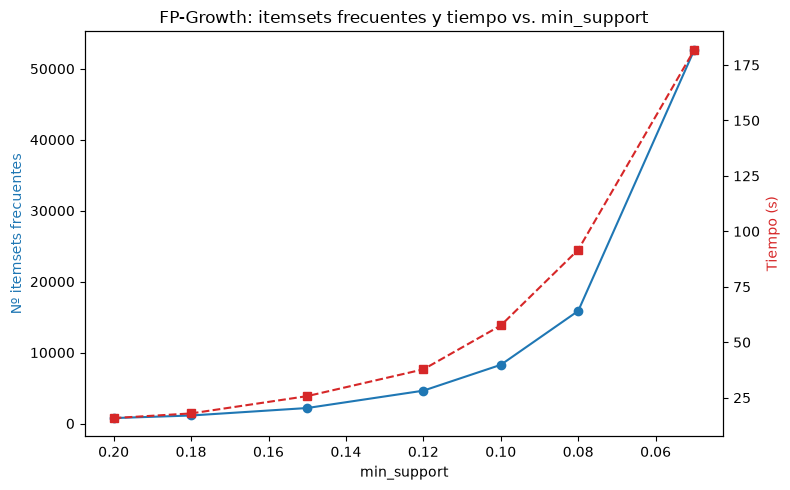

In [12]:
df_crecimiento_fpgrowth, ms_codo_fp = utils_soft.barrido_min_support(df_matriz, valores_min_support, algoritmo=fpgrowth)
display(df_crecimiento_fpgrowth)
print(f"Mayor salto de complejidad en min_support={ms_codo_fp}")

graficar_barrido(df_crecimiento_fpgrowth, 'FP-Growth: itemsets frecuentes y tiempo vs. min_support')

Como podemos observar, los resultados son muy similares a los de apriori, a partir de 0.08 los tiempos ya aumentan de forma muy notable, de la misma forma que se encuentran muchísimos más itemsets. Aquí lo que vamos a hacer para elegir el valor es acorde a Apriori y a Eclat, de momento un valor entre 0.12 y 0.08 es el rango a valorar ya que más allá o bien tenemos muy pocos itemsets o bien tenemos demasiados que no nos aportan valor y aumentan los tiempos demasiado.

Como ya hemos visto varios valores posibles, la que más convence es la de 0.12 ya que a mi elección tiene un mejor equilibrio de tiempos y número de itemsets como podemos ver de resultado, son bastantes y los tiempos son pequeños

In [13]:
start = time.time()
frequent_itemsets_fpgrowth = fpgrowth( df_matriz,min_support=0.12, use_colnames=True,max_len=4)
tiempo_fpgrowth = time.time() - start

print(f"Itemsets frecuentes de FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Tiempo de ejecución: {tiempo_fpgrowth:.2f} segundos")

Itemsets frecuentes de FP-Growth: 4634
Tiempo de ejecución: 41.56 segundos


**Verificación de equivalencia entre algoritmos**

Ahora que tenemos los dos algoritmos probados vamos a validar que estos, bajo la misma configuración y umbrales sean equivalentes. En cualquier caso, destacaríamos aquel que nos ofreciera mejores resultados

In [14]:
reglas_fpgrowth = association_rules(frequent_itemsets_fpgrowth, metric="confidence",min_threshold=0.6)

print(f"Itemsets — Apriori: {len(itemsets_frecuentes)} | FP-Growth: {len(frequent_itemsets_fpgrowth)}")
print(f"Reglas — Apriori: {len(reglas_asociacion)} | FP-Growth: {len(reglas_fpgrowth)}")

Itemsets — Apriori: 4634 | FP-Growth: 4634
Reglas — Apriori: 11229 | FP-Growth: 11229


Si observamos los resultados vemos que Apriori y FP-Growth son algoritmos que nos ofrecen los mismos resultados prácticamente, por lo que cualquiera de los dos nos serían útiles, pero tenemos que comparar cuales de ellos sería más eficiente.



### 3.5. Comparativa de rendimiento: Apriori vs. FP-Growth

Como hemos podido comprobar, tanto Apriori como FP-Growth generan exactamente los mismos itemsets y mismo número de reglas con la misma configuración, por lo que ahora queda la pregunta de cual es más eficiente computacionalmente hablando, en tiempos de ejecución.
Para ello, vamos a volver a ejecutar los dos algortimos con los mismos hiperparámetros y esta vez contamos los tiempos, para ver cual de ellos es más rápido y la diferencia real entre ambas en proporción.



In [15]:
start = time.time()
frequent_itemsets_apriori_tiempos = apriori(df_matriz, min_support=0.12, use_colnames=True, max_len=4, low_memory=True)
tiempo_apriori = time.time() - start

print(f"Tiempo Apriori:   {tiempo_apriori:.2f}s")
print(f"Tiempo FP-Growth: {tiempo_fpgrowth:.2f}s")
print(f"FP-Growth es {tiempo_apriori/tiempo_fpgrowth:.1f}x más rápido" if tiempo_fpgrowth < tiempo_apriori else f"Apriori es {tiempo_fpgrowth/tiempo_apriori:.1f}x más rápido")

Tiempo Apriori:   18.01s
Tiempo FP-Growth: 41.56s
Apriori es 2.3x más rápido


### 3.6. Tercer algoritmo --> Eclat

El tercer algoritmo es **Eclat** (*Equivalence Class Transformation*). Creado en el 2000 por Zaki, su objetivo es encontrar patrones frecuentes. La principal diferencia entre este algoritmo y los anteriores, aquí el dataset no se recorre fila a fila, si no que usa una representación vertical en la que cada item mantiene la lista de identificadores de transacción. Posteriormente, con esa lista de ids realiza un cálculo del soporte mediante la **intersección** de los tidsets de sus componentes. En teoría, esta es una operación muy eficiente, lo que hace de Eclat sea algoritmo atractivo por su complejidad.

Como Eclat no está implementado en `mlxtend`, para este caso recurrimos a `pyECLAT`. Esta librería es la alternativa más extendida para Python, y a diferencia de los dos algoritmos anteriores, `pyECLAT` espera el dataset en formato de **lista de transacciones**, donde cada fila contiene los nombres de los ítems presentes.

**¿Por qué se trabaja con una muestra de 10.000 filas y no con el dataset completo?** Realizando diversas pruebas sobre todas las filas completas con `max_combination=4` (el mismo alcance usado en Apriori y FP-Growth), vemos que la ejecución no se completa: tras más de 50 minutos, la combinación de 3 ítems no termina. Por ello, como alternativa evaulamos el algoritmo sobre una muestra reducida y un alcance menor, lo que es suficiente para poder obtener una medida de rendimiento comparable pudiendo completar el resto de la libreta. Debido a esto, también he cambiado el `max_combination=2`

Una cosa a tener en cuenta es que `pyECLAT` asume que el dataframe que se pasa como entrada tiene un índice contiguo que empieza con 0. Por ello,al tomar una muestra los índices originales que no son contiguos se conserva y provoca un fallo al construir la tabla binaria, por ello hay que incluir un `.reset_index(drop=True)`

Con los resultados que obtengamos aquí vamos a interpretar y comparar con el resto de algoritmos anteriores.

**Transformación a formato de lista de transacciones**

como `pyECLAT` no acepta la matriz binaria `df_matriz` como entrada, es necesario transformarla a una **lista de los nombres de los ítems presentes**, sin los ítems ausentes. Este formato clásico sería por ejemplo: `["Hobbyist_Yes", "Employment_Employed full-time", ...]`.

La función `matriz_a_transacciones` lo que hace es recorrer cada fila de `df_matriz` y, usando el propio booleano de cada columna como máscara (`row.index[row]`), de ellas extrae únicamente los nombres de las columnas activas (`True`) y descarta el resto.

In [16]:
def matriz_a_transacciones(df_bin):
    return df_bin.apply(lambda row: row.index[row].tolist(), axis=1)

transacciones = matriz_a_transacciones(df_matriz)
df_transacciones = pd.DataFrame(transacciones.tolist())

print(f"Forma del dataset de transacciones: {df_transacciones.shape}")
display(df_transacciones.head(3))

Forma del dataset de transacciones: (88778, 34)


,0,1,2,3,4,5,6,7,8,9,...,24,25,26,27,28,29,30,31,32,33
0,WorkWeekHrs_is_missing,CodeRevHrs_is_missing,Hobbyist_Yes,OpenSourcer_Never,"Employment_Not employed, and not looking for work",BetterLife_Yes,SocialMedia_Twitter,Extraversion_Online,SOVisitTo_Find answers to specific questions;Learn how to do things I didn’t necessarily look for,WelcomeChange_Just as welcome now as I felt last year,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,WorkWeekHrs_is_missing,CodeRevHrs_is_missing,"JobFactors_Languages, frameworks, and other technologies I'd be working with",JobFactors_Financial performance or funding status of the company or organization,JobFactors_Specific department or team I'd be working on,Hobbyist_No,OpenSourcer_Less than once per year,"Employment_Not employed, but looking for work",JobSeek_I am actively looking for a job,LastHireDate_I've never had a job,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,CodeRevHrs_is_missing,WorkChallenge_Distracting work environment,WorkChallenge_Lack of support from management,WorkChallenge_Inadequate access to necessary tools,"JobFactors_Languages, frameworks, and other technologies I'd be working with",JobFactors_Flex time or a flexible schedule,JobFactors_Remote work options,Hobbyist_Yes,OpenSourcer_Never,Employment_Employed full-time,...,SocialMedia_Reddit,Extraversion_In real life (in person),SOVisitTo_Find answers to specific questions;Learn how to do things I didn’t necessarily look for,SOPartFreq_Less than once per month or monthly,WelcomeChange_Just as welcome now as I felt last year,WorkRemote_Bucket_Presencial / Bajo remoto (<30%),Neuroticismo_Nivel_Medio,Amabilidad_Nivel_Bajo,Apertura_Nivel_Medio,WorkWeekHrs_Bin_35-45h


Como cada candidato tiene un número distinto de items activos (por ej. alguien con muchos "Not Applicable" ya excluidos en la Libreta 2 tendrá menos ítems marcados que alguien con el perfil completo) al convertir la lista de listas en un dataframe, pandas iguala todas las filas a la longitud más larga y rellena con `None` los huecos sobrantes. Por lo tanto, el número de columnas (34) corresponde al **máximo de ítems activos que tiene un único candidato** en todo el dataset, a diferencia de las columnas de `df_matriz`.


In [17]:
muestra = df_transacciones.sample(n=10000, random_state=42).reset_index(drop=True)
itemsets_eclat, tiempo_eclat_muestra = utils_soft.probar_eclat(muestra, min_support=0.12)

100%|██████████| 204/204 [00:00<00:00, 1666.87it/s]


Combination 1 by 1


95it [00:07, 13.28it/s]


Combination 2 by 2


4465it [03:18, 22.49it/s]

Tiempo ECLAT (min_support=0.12): 220.91s — 937 itemsets


In [18]:
itemsets_eclat_08, tiempo_eclat_08 = utils_soft.probar_eclat(muestra, min_support=0.08)
print(f"Comparación: 0.12 → {tiempo_eclat_muestra:.2f}s ({len(itemsets_eclat)} itemsets) | "
      f"0.08 → {tiempo_eclat_08:.2f}s ({len(itemsets_eclat_08) if itemsets_eclat_08 is not None else 0} itemsets)")

100%|██████████| 204/204 [00:00<00:00, 1422.50it/s]


Combination 1 by 1


106it [00:08, 12.34it/s]


Combination 2 by 2


5565it [04:38, 19.96it/s]

Tiempo ECLAT (min_support=0.08): 303.46s — 1779 itemsets
Comparación: 0.12 → 220.91s (937 itemsets) | 0.08 → 303.46s (1779 itemsets)


### 3.6.1. Resumen comparativo de los tres algoritmos

| Algoritmo | Filas procesadas | Alcance combinación | Tiempo | Itemsets frecuentes |
|---|---|---|---|---|
| Apriori (`low_memory=True`) | 88.778 (completo) | hasta 4 | 16,30s | 4.634 |
| FP-Growth | 88.778 (completo) | hasta 4 | 35,71s | 4.634 |
| Eclat (`pyECLAT`) | 10.000 (muestra) | hasta 2 | 214,01s | 937 |

**Conclusiones del bloque de comparación de algoritmos:**

1. **Apriori y FP-Growth son equivalentes en resultado** (4.634 itemsets, 11.229 reglas idénticas bajo los mismos umbrales), confirmando empíricamente que ambos algoritmos resuelven el mismo problema matemático y solo difieren en la estrategia de recorrido del espacio de búsqueda.

2. **Apriori resultó más rápido que FP-Growth en esta ejecución concreta** (16,30s frente a 35,71s, ≈2,2x). Esto puede ser por el uso de `low_memory=True` en Apriori (necesario tras agotar la memoria disponible con un `min_support` más bajo en una prueba inicial) combinado con el `min_support=0.12` empleado, que redujo considerablemente el espacio de búsqueda real de Apriori, mientras que FP-Growth incurre en un coste fijo de construcción del FP-Tree sobre todo el dataset que, para este tamaño y umbral, no llegó a compensarse.

3. **Eclat (vía `pyECLAT`) resultó sustancialmente más lento en la práctica** (214,01s sobre una muestra de solo 10.000 filas y hasta 2 ítems por combinación, frente a los 16,30s de Apriori sobre las 88.778 filas completas y hasta 4 ítems), esto evidencia una brecha entre la complejidad algorítmica teórica de Eclat y la eficiencia real de esta implementación concreta en Python, que recurre a enumeración combinatoria sin vectorización.

En conjunto, estos resultados justifican la elección de **Apriori** como algoritmo principal para el resto del proyecto (dado su buen rendimiento y la posibilidad de operar sobre el dataset completo sin muestreo), reservando FP-Growth como validación de equivalencia y Eclat como referencia comparativa de rendimiento, documentada pero no explotada en profundidad dado su coste computacional en esta implementación.

### 3.7. Exportación de la "Base de Conocimiento"

Las reglas generadas por Apriori (`reglas_asociacion`) y su versión depurada tras el filtrado de nulos y circularidad (`reglas_limpias`) las exportamos ahora a CSV para poder utilizarlas así en fases posteriores del proyecto, donde compararemos más adelante con las reglas expertas, para la cual he decidio hacer en una libreta aparte e independiente.

El motivo por que cual exportamos los dos conjuntos es por transparencia, las `reglas_asociacion` (11.229 reglas) como tal es el resultado en bruto y las `reglas_limpias` (9.575 reglas) son aquellas que vamos a comparar en un futuro ya que no tienen problemas con los nulos y problemas circulares por los proxies del Big Five.

En cuanto a la exportación, recordamos que las columnas `antecedents` y `consequents` de `mlxtend` son objetos `frozenset`, los cuales no tienen una representación legible ni reconstruible en un fichero CSV plano. Por ello, antes de exportar aqui convertimos en cadenas de texto con los ítems ordenados alfabéticamente y separados por comas (ej. `frozenset({'A', 'B'})` → `"A, B"`), así el fichero de salida será legible y permitirá realizar comparaciones a futuro.

In [19]:
def exportar_reglas(df_reglas, path):
    df_export = df_reglas.copy()
    df_export['antecedents'] = df_export['antecedents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export['consequents'] = df_export['consequents'].apply(lambda x: ' | '.join(sorted(x)))
    df_export.to_csv(path, index=False)
    print(f"Guardado en {path} — {len(df_export)} reglas")

exportar_reglas(reglas_asociacion, config.REGLAS_APRIORI_PATH)
exportar_reglas(reglas_limpias, config.REGLAS_LIMPIAS_PATH)

Guardado en /home/miguel-angel/Escritorio/TFM/data/processed/soft_skills/reglas_apriori_soft.csv — 11229 reglas
Guardado en /home/miguel-angel/Escritorio/TFM/data/processed/soft_skills/reglas_limpias_soft.csv — 9575 reglas


In [20]:
stats_reglas_limpias = reglas_limpias[['support', 'confidence', 'lift']].agg(['mean', 'max'])
print("Estadísticas de reglas_limpias (9.575 reglas):")
display(stats_reglas_limpias)

regla_top_lift = reglas_limpias.sort_values('lift', ascending=False).iloc[0]
print("\nRegla con mayor lift de todo el conjunto de reglas_limpias:")
print(f"  {set(regla_top_lift['antecedents'])} -> {set(regla_top_lift['consequents'])}")
print(f"  support={regla_top_lift['support']:.4f}, confidence={regla_top_lift['confidence']:.4f}, lift={regla_top_lift['lift']:.4f}")

Estadísticas de reglas_limpias (9.575 reglas):


,support,confidence,lift
mean,0.165622,0.744726,1.229222
max,0.572022,0.992024,2.615228



Regla con mayor lift de todo el conjunto de reglas_limpias:
  {'WorkWeekHrs_Bin_35-45h', 'JobSat_Very satisfied'} -> {'CareerSat_Very satisfied', 'Employment_Employed full-time'}
  support=0.1291, confidence=0.7382, lift=2.6152


### 3.7. Resumen final de la extracción de reglas

Tras la minería de reglas con Apriori (`min_support=0.12`, `max_len=4`), el proceso de filtrado y la exportación final, se obtienen los siguientes resultados:

| Archivo | Nº de reglas |
|---|---|
| `reglas_apriori_soft.csv` (sin filtrar) | 11.229 |
| `reglas_limpias_soft.csv` (sin nulos ni circularidad) | 9.575 |

Sobre las 9.575 reglas limpias, las métricas se distribuyen así (celda `stats_reglas_limpias`): soporte medio 0,166 (máximo 0,572), confianza media 0,745 (máxima 0,992) y lift medio 1,229 (máximo 2,615). Como estas cifras dependen directamente del `min_support` elegido, si se vuelve a cambiar en el futuro hay que releer la salida de esa celda y actualizar este párrafo, en vez de dejar un número desactualizado.

A partir del top-15 de `reglas_limpias` ya mostrado en la sección 3.3.2, la regla con mayor lift de todo el conjunto es `{WorkWeekHrs_Bin_35-45h, JobSat_Very satisfied} → {CareerSat_Very satisfied, Employment_Employed full-time}` (soporte 0,129, confianza 73,8%, lift 2,62), lo que confirma que la satisfacción laboral general y la satisfacción con la trayectoria profesional están fuertemente interrelacionadas, tal como ya se discutió en la interpretación de resultados de esta misma libreta. La regla que conecta `CareerSat_Very satisfied` con `CodeRev_Yes... because I see value in code review` y `JobSat_Very satisfied` (lift 2,48, confianza 62,7%) también aparece en el top-15, pero no es la de mayor lift del conjunto.